# Verification: symmetric bivalent hapten-receptor cross-linking, no rings (Dembo and Goldstein, 1978)

`blbr_dembo1978.bngl` is run network-free by **BioNetGen's own NFsim** (`simulate({method=>"nf"})`
with `-bscb`), and checked against theory that shares no code with BioNetGen:

* **Exact equilibrium (asserted).** With `-bscb` no bond can close a ring, every aggregate is a
  linear chain, and every rule has its reverse, so the stationary state satisfies detailed
  balance. In the large-system limit its site-level statistics are those of Dembo and Goldstein
  (1978) with J1 = J2 = 0, in the per-site form of Perelson and DeLisi (1980): singly bound
  hapten m = 2K1·L·S, doubly bound (cross-linking) hapten M = K1·K2·L·S², free receptor sites S
  from S_T = S + m + 2M with L = L_T/(1 + 2K1·S + K1·K2·S²), and, because the two sites of a
  receptor are independent, free receptors R_free = R_T·(S/S_T)². K1 = kf/koff and K2 = kxf/koff
  are the per-site-pair constants of the file.
* **Kinetics (asserted at fixed times).** The Perelson-DeLisi equations for m(t), M(t),
  integrated by SciPy from the all-free start.

Three hapten doses span the bell-shaped cross-linking curve: below the optimum, the file's own
dose (KC = 2K1·L_T ≈ 1, the optimum), and above it (prozone). **Only `LT_per_cell` changes**;
the subvolume stays at the file's f = 0.01 (R_T = 3000), so the middle dose *is* the committed
file. Each dose runs **20 replicates with distinct seeds**, and every tolerance below is set
from the replicate-to-replicate standard error.

**Combinatorial mapping.** For `L(r,r) + R(l) -> L(r!1,r).R(l!1) kf` a free L has two
equivalent r sites, so BioNetGen fires at 2·kf per (free L, free R site) pair; crosslinking
fires at kxf per (dangling arm, free site) pair; each bond breaks at koff.

In [1]:
import atexit, os, re, shutil, subprocess, tempfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
from scipy import stats
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
import matplotlib.pyplot as plt

HERE = Path.cwd()
STEM = "blbr_dembo1978"
BNGL = (HERE / f"{STEM}.bngl").read_text()

def find_bionetgen():
    # BNG2.pl from $BNG2_PL or $BNGPATH, then BNG2.pl on PATH, then the `bionetgen` CLI.
    for cand in (os.environ.get("BNG2_PL"),
                 str(Path(os.environ["BNGPATH"]) / "BNG2.pl") if os.environ.get("BNGPATH") else None,
                 shutil.which("BNG2.pl")):
        if cand and Path(cand).is_file():
            return str(Path(cand).absolute()), False
    cli = shutil.which("bionetgen")
    if cli:
        return cli, True
    raise FileNotFoundError("BioNetGen not found: set BNG2_PL (or BNGPATH) to a BioNetGen 2.9.3 "
                            "BNG2.pl, or put the bionetgen CLI on PATH.")

BNG, USE_CLI = find_bionetgen()
print("BioNetGen:", BNG)

# Constants, checked against the file's parameter block so the theory cannot drift from it.
NA = 6.02214076e23; V_cell = 1e-9; R_per_cell = 3e5; f = 0.01
kon = 1e6; koff = 0.01; KxRT = 5; LT_file = 3e6
for name, val in [("NA", NA), ("V_cell", V_cell), ("R_per_cell", R_per_cell), ("f", f),
                  ("kon", kon), ("koff", koff), ("KxRT", KxRT), ("LT_per_cell", LT_file)]:
    m = re.search(rf"^\s*{name}\s+([0-9.eE+-]+)\s", BNGL, re.M)
    assert m and float(m.group(1)) == val, f"{name} in the .bngl is not {val}"
V_sim = V_cell * f; RT = R_per_cell * f; ST = 2 * RT
kf = kon / (NA * V_sim); kxf = KxRT / RT * koff
K1 = kf / koff; K2 = kxf / koff

DOSES = {"below": 3e5, "file (optimal)": 3e6, "above": 3e7}   # LT_per_cell
N_REP = 20
SEEDS = {lab: [1000 * (k + 1) + i for i in range(1, N_REP + 1)] for k, lab in enumerate(DOSES)}
t_end = 3000; n_steps = 300
print(f"RT = {RT:.0f}, ST = {ST:.0f}, K1 = {K1:.4e}, K2 = {K2:.4e}")
for lab, LTc in DOSES.items():
    print(f"  {lab:15s} LT_per_cell = {LTc:.0e}: LT = {LTc*f:.0f}, KC = 2*K1*LT = {2*K1*LTc*f:.2f}, "
          f"particles = {LTc*f + RT:.0f}, seeds {SEEDS[lab][0]}..{SEEDS[lab][-1]}")

BioNetGen: /vast/home/wish/wt/scratch/bng-loader/BioNetGen-2.9.3/BNG2.pl
RT = 3000, ST = 6000, K1 = 1.6605e-05, K2 = 1.6667e-03
  below           LT_per_cell = 3e+05: LT = 3000, KC = 2*K1*LT = 0.10, particles = 6000, seeds 1001..1020
  file (optimal)  LT_per_cell = 3e+06: LT = 30000, KC = 2*K1*LT = 1.00, particles = 33000, seeds 2001..2020
  above           LT_per_cell = 3e+07: LT = 300000, KC = 2*K1*LT = 9.96, particles = 303000, seeds 3001..3020


## Kinetic ODEs and the exact equilibrium

$$\frac{dm}{dt} = 2 k_f L S - k_{\text{off}} m - k_{xf} m S + 2 k_{\text{off}} M,\qquad
\frac{dM}{dt} = k_{xf} m S - 2 k_{\text{off}} M,$$
with $S = S_T - m - 2M$ and $L = L_T - m - M$. The equilibrium is solved directly (a 1-D root
in S), not read off the ODE, and the two are required to agree. The ODE also fixes the
**equilibrium window**: the NFsim averages are taken over t ≥ 1800 s, and the assert below
requires that the mean-field transient there is below 1e-4 of the equilibrium at every dose, so
the window adds no bias the tolerances must absorb.

In [2]:
def odes(t, y, LT):
    m, M = y
    S = ST - m - 2 * M; L = LT - m - M
    return [2 * kf * L * S - koff * m - kxf * m * S + 2 * koff * M, kxf * m * S - 2 * koff * M]

def exact_equilibrium(LT):
    def g(S):
        L = LT / (1 + 2 * K1 * S + K1 * K2 * S**2)
        return S - (ST - 2 * K1 * L * S - 2 * K1 * K2 * L * S**2)
    S = brentq(g, 1e-12, ST, xtol=1e-12, rtol=1e-14)
    L = LT / (1 + 2 * K1 * S + K1 * K2 * S**2)
    m = 2 * K1 * L * S; M = K1 * K2 * L * S**2
    return dict(S=S, L=L, m=m, M=M, Bonds=m + 2 * M, Rfree=RT * (S / ST)**2)

T_EQ0 = 1800.0
tgrid = np.linspace(0, t_end, n_steps + 1)
ode, eq, t_relax = {}, {}, {}
for lab, LTc in DOSES.items():
    LT = LTc * f
    sol = solve_ivp(odes, (0, t_end), [0.0, 0.0], args=(LT,), method="LSODA",
                    rtol=1e-11, atol=1e-10, t_eval=tgrid)
    m, M = sol.y
    ode[lab] = dict(Bonds=m + 2 * M, M=M)
    eq[lab] = e = exact_equilibrium(LT)
    rel = np.maximum(np.abs(ode[lab]["Bonds"] / e["Bonds"] - 1), np.abs(M / e["M"] - 1))
    t_relax[lab] = {tol: tgrid[np.where(rel > tol)[0].max() + 1] for tol in (1e-2, 1e-3, 1e-4)}
    late = rel[tgrid >= T_EQ0].max()
    assert late < 1e-4, f"{lab}: mean-field transient {late:.1e} inside the equilibrium window"
    print(f"{lab:15s} exact: Bonds/ST = {e['Bonds']/ST:.5f}, M/RT = {e['M']/RT:.5f}, "
          f"R_free/RT = {e['Rfree']/RT:.5f};  ODE(3000 s) - exact: {rel[-1]:.1e};  "
          "within 1%/0.1%/0.01% from t = " + "/".join(f"{t_relax[lab][k]:.0f}" for k in (1e-2, 1e-3, 1e-4))
          + f" s;  Bonds(40 s)/eq = {ode[lab]['Bonds'][4]/e['Bonds']:.3f}")

below           exact: Bonds/ST = 0.32696, M/RT = 0.28467, R_free/RT = 0.45298;  ODE(3000 s) - exact: 2.1e-07;  within 1%/0.1%/0.01% from t = 900/1350/1800 s;  Bonds(40 s)/eq = 0.174
file (optimal)  exact: Bonds/ST = 0.75579, M/RT = 0.53622, R_free/RT = 0.05964;  ODE(3000 s) - exact: 6.7e-16;  within 1%/0.1%/0.01% from t = 220/340/460 s;  Bonds(40 s)/eq = 0.564
above           exact: Bonds/ST = 0.94008, M/RT = 0.35223, R_free/RT = 0.00359;  ODE(3000 s) - exact: 0.0e+00;  within 1%/0.1%/0.01% from t = 130/210/300 s;  Bonds(40 s)/eq = 0.996


## The committed file against its reference, then the NFsim ensembles

Every run is the committed `.bngl` with at most three literal substitutions, each asserted to
occur exactly once: the dose (`LT_per_cell`), the seed, and `get_final_state=>0`. The last one only
stops BNG2.pl from reading NFsim's final species list back in after the run (and NFsim from
writing it): the trajectory is unchanged, which the reproduction check below shows, and the
read-back is very expensive on this file: at the default dose BNG2.pl's Perl was still labelling
the final chains canonically after 19 minutes, against about 4 s of CPU for NFsim's own run.

First the file itself (seed 42, its own dose) is held to the house reproduction rule against
`reference/blbr_dembo1978_nfr.gdat`: relative error ≤ 1e-3 or absolute error ≤ 1e-6 × the column
maximum. Then 20 seeds per dose, run in a temporary directory that is removed afterwards
(`VERIFY_WORKERS`, default 2, sets the number of concurrent BNG2.pl processes).

In [3]:
TMP = Path(tempfile.mkdtemp(prefix="verify_dembo1978_", dir=HERE))
atexit.register(shutil.rmtree, TMP, ignore_errors=True)   # also on a failed assert

def edit(text, old, new):
    assert text.count(old) == 1, f"expected exactly one {old!r} in the .bngl"
    return text.replace(old, new)

def run_nf(LTc, seed, name):
    text = BNGL
    if LTc != LT_file:
        text = edit(text, "LT_per_cell  3e6  # molecules/cell", f"LT_per_cell  {LTc:.0e}  # molecules/cell")
    text = edit(text, 'seed=>42,param=>"-bscb"', f'seed=>{seed},get_final_state=>0,param=>"-bscb"')
    d = TMP / name; d.mkdir()
    p = d / f"{name}.bngl"; p.write_text(text)
    cmd = ([BNG, "run", "-i", str(p), "-o", str(d)] if USE_CLI
           else ["perl", BNG, "--outdir", str(d), str(p)])
    r = subprocess.run(cmd, capture_output=True, text=True, cwd=d)
    assert r.returncode == 0, r.stdout[-3000:] + r.stderr[-3000:]
    assert "-bscb" in r.stdout and "NFsim" in r.stdout, "NFsim was not run with -bscb"
    g = np.loadtxt(d / f"{name}_nfr.gdat")
    shutil.rmtree(d)
    return g

COLS = ["time", "Obs_Free_L", "Obs_Free_R", "Obs_Bonds", "Obs_Free_L_sites", "Obs_Free_R_sites"]
assert open(HERE / "reference" / f"{STEM}_nfr.gdat").readline().split()[1:] == COLS

fresh = run_nf(LT_file, 42, "file_seed42")
ref = np.loadtxt(HERE / "reference" / f"{STEM}_nfr.gdat")
assert fresh.shape == ref.shape, (fresh.shape, ref.shape)
atol = 1e-6 * np.maximum(np.abs(ref).max(axis=0), 1e-300)
ok = (np.abs(fresh - ref) <= 1e-3 * np.abs(ref)) | (np.abs(fresh - ref) <= atol)
assert ok.all(), "the fresh seed-42 run does not reproduce reference/blbr_dembo1978_nfr.gdat"
print(f"seed 42 at the file's dose reproduces reference/{STEM}_nfr.gdat: "
      f"max |fresh - committed| = {np.abs(fresh - ref).max():g}")

jobs = [(lab, LTc, s) for lab, LTc in DOSES.items() for s in SEEDS[lab]]
with ThreadPoolExecutor(int(os.environ.get("VERIFY_WORKERS", "2"))) as pool:
    out = list(pool.map(lambda j: run_nf(j[1], j[2], f"{j[0].split()[0]}_s{j[2]}"), jobs))
shutil.rmtree(TMP)

nf = {}
for lab, LTc in DOSES.items():
    g = np.array([o for (l, _, _), o in zip(jobs, out) if l == lab])     # (rep, time, col)
    assert g.shape == (N_REP, n_steps + 1, len(COLS)) and np.allclose(g[:, :, 0], tgrid)
    LT = LTc * f
    Bonds = g[:, :, 3]
    assert np.all(Bonds + g[:, :, 5] == ST) and np.all(Bonds + g[:, :, 4] == 2 * LT)
    nf[lab] = dict(Bonds=Bonds, M=Bonds - (LT - g[:, :, 1]), Rfree=g[:, :, 2])
    print(f"{lab:15s} {N_REP} seeds: mean Bonds(3000 s) = {Bonds[:, -1].mean():.1f}")

seed 42 at the file's dose reproduces reference/blbr_dembo1978_nfr.gdat: max |fresh - committed| = 0


below           20 seeds: mean Bonds(3000 s) = 1959.0
file (optimal)  20 seeds: mean Bonds(3000 s) = 4530.1
above           20 seeds: mean Bonds(3000 s) = 5634.7


## Level 1a — equilibrium against the exact theory (asserted)

For each replicate the observable is averaged over the equilibrium window (t ≥ 1800 s, 121
output times); the replicates are independent, so the standard error of the dose mean is
s/√20 and needs no assumption about autocorrelation inside a run. Three quantities per dose:
bonds per receptor site, **cross-links** M (doubly bound haptens, the quantity the
Dembo-Goldstein theory is about) per receptor, and free receptors, which tests the
site-independence that makes chains, rather than any other aggregate, the equilibrium state.

**Tolerance: |z| < 4**, z = (NFsim mean − exact)/SE. Under a correct model z follows Student's t
with 19 degrees of freedom; P(|t₁₉| > 4) = 7.6e-4, so the nine comparisons have a family-wise
false-alarm rate below 1%. The theory is the large-system limit and the simulation has
R_T = 3000: the finite-size correction to a mean count is of order one molecule, which is
comparable to the standard errors printed below (0.1 to 5 molecules). No allowance is added
for it, so the test also bounds it: a correction larger than a few standard errors would fail.
The tolerance is tight in absolute terms — a fraction of a percent on every quantity — so a wrong
combinatorial factor (a factor-of-2 slip moves the equilibrium by tens of percent) or a leak of
same-complex binding past `-bscb` would fail it.

In [4]:
win = tgrid >= T_EQ0
Z_EQ = 4.0
print(f"false-alarm rate per comparison at |z| > {Z_EQ}: {2*stats.t.sf(Z_EQ, N_REP-1):.1e}")
norm = {"Bonds": ("Bonds/ST", ST), "M": ("M/RT", RT), "Rfree": ("R_free/RT", RT)}
eq_rows = []
for lab in DOSES:
    for key, (name, den) in norm.items():
        x = nf[lab][key][:, win].mean(axis=1) / den
        mean, se = x.mean(), x.std(ddof=1) / np.sqrt(N_REP)
        th = eq[lab][key] / den
        eq_rows.append((lab, name, mean, se, th, (mean - th) / se, mean / th - 1))
print(f"{'dose':15s} {'quantity':10s} {'NFsim':>9s} {'SE':>8s} {'exact':>9s} {'z':>6s} {'rel':>8s}")
for lab, name, mean, se, th, z, rel in eq_rows:
    print(f"{lab:15s} {name:10s} {mean:9.5f} {se:8.5f} {th:9.5f} {z:6.2f} {rel:8.1e}")
max_z_eq = max(abs(r[5]) for r in eq_rows)
print(f"max |z| = {max_z_eq:.2f} (tolerance {Z_EQ}); max |relative error| = "
      f"{max(abs(r[6]) for r in eq_rows):.1e}")

false-alarm rate per comparison at |z| > 4.0: 7.7e-04
dose            quantity       NFsim       SE     exact      z      rel
below           Bonds/ST     0.32725  0.00087   0.32696   0.34  9.0e-04
below           M/RT         0.28491  0.00073   0.28467   0.33  8.5e-04
below           R_free/RT    0.45229  0.00119   0.45298  -0.58 -1.5e-03
file (optimal)  Bonds/ST     0.75567  0.00027   0.75579  -0.46 -1.7e-04
file (optimal)  M/RT         0.53638  0.00024   0.53622   0.67  3.0e-04
file (optimal)  R_free/RT    0.05972  0.00017   0.05964   0.52  1.5e-03
above           Bonds/ST     0.94015  0.00008   0.94008   0.86  7.1e-05
above           M/RT         0.35207  0.00033   0.35223  -0.47 -4.4e-04
above           R_free/RT    0.00355  0.00003   0.00359  -1.66 -1.2e-02
max |z| = 1.66 (tolerance 4.0); max |relative error| = 1.2e-02


## Level 1b — kinetics against the Perelson-DeLisi ODEs (asserted at fixed times)

The ensemble mean of bonds and cross-links is compared with the ODE at **t = 10, 40, 100, 300
and 1000 s**: early rise, the bngsim paper's 40 s benchmark horizon, the approach to
equilibrium, and the slow tail of the low dose. z is formed as above from the 20 replicates at
that output time. **Tolerance: |z| < 4.5** — 30 comparisons, P(|t₁₉| > 4.5) = 2.4e-4 each, so a
family-wise false-alarm rate below 1%. The ODE is the mean-field limit of the same rules, exact
to order 1/R_T for the mean, and the intra-complex pairs that `-bscb` removes from the
crosslinking propensity are a 1e-4 fraction of all pairs, both far below the standard errors.
Over every output time before the window the maximum |z| and the fraction below 3 are reported
as the house diagnostic (`network-free-verification.md` §5), not asserted: those 700-odd
comparisons are strongly correlated in time.

In [5]:
T_CHECK = [10, 40, 100, 300, 1000]
Z_KIN = 4.5
print(f"false-alarm rate per comparison at |z| > {Z_KIN}: {2*stats.t.sf(Z_KIN, N_REP-1):.1e}")
zt, kin_rows = {}, []
for lab in DOSES:
    zt[lab] = {}
    for key in ("Bonds", "M"):
        x = nf[lab][key]
        se = x.std(axis=0, ddof=1) / np.sqrt(N_REP)
        z = np.where(se > 0, (x.mean(axis=0) - ode[lab][key]) / np.where(se > 0, se, 1), 0.0)
        zt[lab][key] = z
        for tc in T_CHECK:
            i = int(np.argmin(np.abs(tgrid - tc)))
            kin_rows.append((lab, key, tc, x[:, i].mean(), ode[lab][key][i], z[i]))
print(f"{'dose':15s} {'obs':5s} {'t (s)':>6s} {'NFsim':>9s} {'ODE':>9s} {'z':>6s}")
for lab, key, tc, mean, o, z in kin_rows:
    print(f"{lab:15s} {key:5s} {tc:6d} {mean:9.1f} {o:9.1f} {z:6.2f}")
max_z_kin = max(abs(r[5]) for r in kin_rows)
pre = (tgrid > 0) & (tgrid < T_EQ0)
allz = np.concatenate([zt[l][k][pre] for l in DOSES for k in ("Bonds", "M")])
diag = (f"all {allz.size} transient comparisons: max |z| = {np.abs(allz).max():.2f}, "
        f"fraction |z| < 3 = {np.mean(np.abs(allz) < 3):.3f}")
print(f"checkpoint max |z| = {max_z_kin:.2f} (tolerance {Z_KIN});  {diag}")

false-alarm rate per comparison at |z| > 4.5: 2.5e-04
dose            obs    t (s)     NFsim       ODE      z
below           Bonds     10      76.7      76.6   0.06
below           Bonds     40     343.9     341.1   0.46
below           Bonds    100     772.8     773.5  -0.09
below           Bonds    300    1542.7    1536.6   0.57
below           Bonds   1000    1943.9    1950.0  -0.81
below           M         10      20.5      19.9   0.61
below           M         40     136.7     135.8   0.32
below           M        100     332.1     332.7  -0.14
below           M        300     674.0     671.6   0.44
below           M       1000     846.8     849.0  -0.58
file (optimal)  Bonds     10     714.8     717.9  -0.49
file (optimal)  Bonds     40    2552.5    2557.6  -0.64
file (optimal)  Bonds    100    4020.9    4020.3   0.08
file (optimal)  Bonds    300    4519.1    4525.8  -1.06
file (optimal)  Bonds   1000    4529.1    4534.8  -0.63
file (optimal)  M         10     178.7     180.8  

## Verification figure and verdict

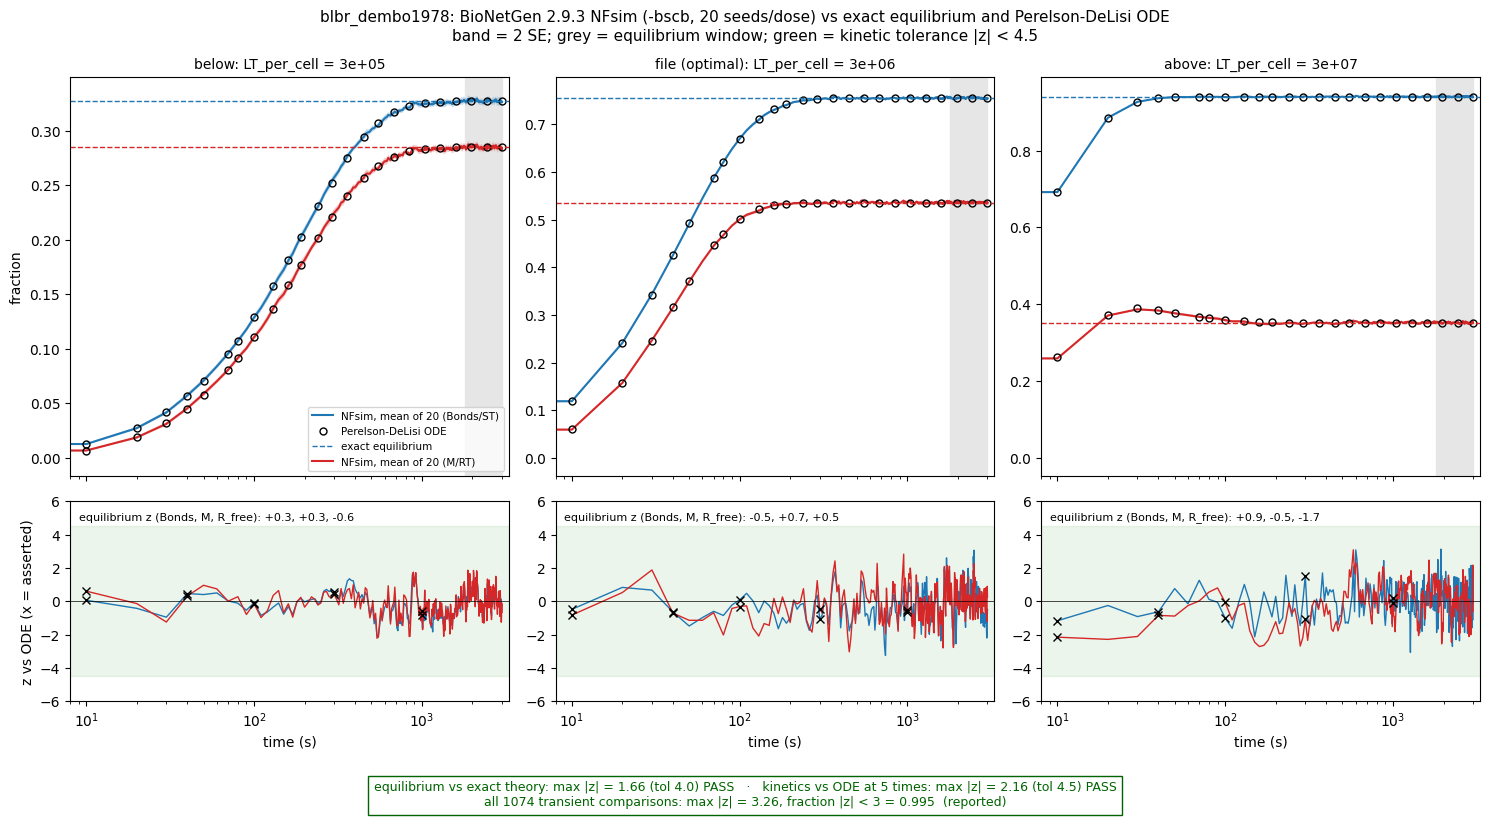

PASS: NFsim (BNG2.pl, -bscb) agrees with the exact equilibrium and the Perelson-DeLisi kinetics.


In [6]:
import sys
sys.path.insert(0, str(HERE.parents[1] / "skills/curate-model/scripts"))
from verification_figure import verdict_footer

pass_eq, pass_kin = max_z_eq < Z_EQ, max_z_kin < Z_KIN
MK = np.unique(np.round(np.geomspace(1, n_steps, 28)).astype(int))   # log-spaced ODE markers
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2), sharex=True,
                         gridspec_kw={"height_ratios": [2.0, 1.0]})
for col, lab in enumerate(DOSES):
    ax = axes[0, col]
    for key, c in (("Bonds", "C0"), ("M", "C3")):
        den = ST if key == "Bonds" else RT
        x = nf[lab][key] / den
        mu, se = x.mean(axis=0), x.std(axis=0, ddof=1) / np.sqrt(N_REP)
        ax.plot(tgrid, mu, color=c, lw=1.5, label=f"NFsim, mean of {N_REP} ({'Bonds/ST' if key=='Bonds' else 'M/RT'})")
        ax.fill_between(tgrid, mu - 2 * se, mu + 2 * se, color=c, alpha=0.25, lw=0)
        ax.plot(tgrid[MK], ode[lab][key][MK] / den, "o", mfc="none", ms=5, color="k",
                label="Perelson-DeLisi ODE" if key == "Bonds" else None)
        ax.axhline(eq[lab][key] / den, color=c, ls="--", lw=1,
                   label="exact equilibrium" if key == "Bonds" else None)
    ax.axvspan(T_EQ0, t_end, color="0.9", zorder=0)
    ax.set_xscale("log"); ax.set_xlim(8, t_end * 1.1)
    ax.set_title(f"{lab}: LT_per_cell = {DOSES[lab]:.0e}", fontsize=10)
    ax.set_ylabel("fraction" if col == 0 else "")
    if col == 0:
        ax.legend(fontsize=7.5, loc="lower right")
    ax = axes[1, col]
    for key, c in (("Bonds", "C0"), ("M", "C3")):
        ax.plot(tgrid[1:], zt[lab][key][1:], color=c, lw=1)
    for lab2, key, tc, _, _, z in kin_rows:
        if lab2 == lab:
            ax.plot(tc, z, "kx", ms=6)
    ax.axhspan(-Z_KIN, Z_KIN, color="g", alpha=0.08)
    ax.axhline(0, color="k", lw=0.5)
    zeq = [r[5] for r in eq_rows if r[0] == lab]
    ax.text(0.02, 0.95, "equilibrium z (Bonds, M, R_free): " + ", ".join(f"{z:+.1f}" for z in zeq), transform=ax.transAxes,
            fontsize=8, va="top")
    ax.set_xscale("log"); ax.set_xlim(8, t_end * 1.1)
    ax.set_ylim(-6, 6)
    ax.set_xlabel("time (s)")
    ax.set_ylabel("z vs ODE (x = asserted)" if col == 0 else "")
fig.suptitle("blbr_dembo1978: BioNetGen 2.9.3 NFsim (-bscb, 20 seeds/dose) vs exact equilibrium and "
             "Perelson-DeLisi ODE\nband = 2 SE; grey = equilibrium window; green = kinetic tolerance |z| < 4.5",
             fontsize=11)
fig.tight_layout(rect=(0, 0.06, 1, 1))
verdict_footer(fig, [
    f"equilibrium vs exact theory: max |z| = {max_z_eq:.2f} (tol {Z_EQ}) {'PASS' if pass_eq else 'FAIL'}",
    f"kinetics vs ODE at 5 times: max |z| = {max_z_kin:.2f} (tol {Z_KIN}) {'PASS' if pass_kin else 'FAIL'}",
], extra=diag + "  (reported)")
fig.savefig("verify_dembo1978.png", dpi=150, bbox_inches="tight")
plt.show()

assert pass_eq, f"equilibrium: max |z| = {max_z_eq:.2f} >= {Z_EQ}"
assert pass_kin, f"kinetics: max |z| = {max_z_kin:.2f} >= {Z_KIN}"
print("PASS: NFsim (BNG2.pl, -bscb) agrees with the exact equilibrium and the Perelson-DeLisi kinetics.")

## Protocol notes

* **Horizon.** The file simulates 3000 s. At the file's dose the mean-field approach to
  equilibrium (bonds and cross-links) is within 1% by 220 s, 0.1% by 340 s and 0.01% by 460 s
  (printed above), so about 85% of the 3000 s samples a stationary state. The bngsim paper's network-free benchmark (B17) ran
  this file to **t_end = 40 s**, where the bond count is only about 56% of its equilibrium
  value: that horizon times the rising transient, not the equilibrium this record verifies.
* **Seeds.** The file pins `seed=>42` so that `reference/` is an exact regression baseline;
  the ensembles here use seeds 1001-1020, 2001-2020 and 3001-3020.
* **Flags.** `-bscb` is the model: it is what makes the aggregates chains (J1 = J2 = 0).
  No `-utl` is set: the largest pattern spans two molecules, and the checks above pass at
  NFsim's auto-computed traversal limit.